## SCRAPPING DATA

In [4]:
!pip install google-play-scraper langdetect pandas


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd
from google_play_scraper import reviews, Sort

apps = {
    "Netflix": "com.netflix.mediaclient",
    "Disney+": "com.disney.disneyplus",
    "Viu": "com.vuclip.viu",
    "HBO Max": "com.wbd.stream",
    "Prime Video": "com.amazon.avod.thirdpartyclient"
}

TARGET_PER_APP = 600
all_reviews = []

for app_name, app_id in apps.items():
    collected = 0
    token = None
    while collected < TARGET_PER_APP:
        result, token = reviews(
            app_id,
            lang='en',
            country='us',
            sort=Sort.NEWEST,
            count=200,
            continuation_token=token
        )
        if not result:
            break
        for r in result:
            r['app_name'] = app_name
        all_reviews.extend(result)
        collected += len(result)
        if token is None:
            break
    print(f"{app_name}: {collected} reviews collected")

df_raw = pd.DataFrame(all_reviews)
print("Total raw data:", len(df_raw))
df_raw.head()

Netflix: 600 reviews collected
Disney+: 600 reviews collected
Viu: 600 reviews collected
HBO Max: 600 reviews collected
Prime Video: 600 reviews collected
Total raw data: 3000


,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion,app_name
0,4d15819d-26f4-4deb-a944-0a6d81aabb72,Emily Pollock,https://play-lh.googleusercontent.com/a-/ALV-U...,Netflix is a really good streaming service wit...,5,0,9.89.0 build 14 74684,2026-10-30 14:26:24,NaN,NaT,9.89.0 build 14 74684,Netflix
1,5944682c-0259-404c-a065-749c4e8b4ba0,Sanjana Naik,https://play-lh.googleusercontent.com/a-/ALV-U...,nice movie ❤️,5,0,9.89.0 build 14 74684,2026-10-30 14:00:32,NaN,NaT,9.89.0 build 14 74684,Netflix
2,3e5dbfe4-4a45-43cb-9052-a90610b72f66,Sanskar Patidar,https://play-lh.googleusercontent.com/a/ACg8oc...,nice,4,0,9.89.0 build 14 74684,2026-10-30 13:57:10,NaN,NaT,9.89.0 build 14 74684,Netflix
3,1c8c2495-eab4-4aa4-a5ad-3c1270d9511e,Sabiha Anwar,https://play-lh.googleusercontent.com/a-/ALV-U...,there is no a lil bit old movies here,2,0,9.89.0 build 14 74684,2026-10-30 13:48:32,NaN,NaT,9.89.0 build 14 74684,Netflix
4,eed43f36-c52e-4d59-b875-6cc94d5274d1,Muaz Muhd,https://play-lh.googleusercontent.com/a-/ALV-U...,this app was fun and easy to use,5,0,9.90.0 build 10 74712,2026-10-30 13:29:09,NaN,NaT,9.90.0 build 10 74712,Netflix


In [6]:
from langdetect import detect

df = df_raw[['app_name', 'content', 'score', 'at']].copy()

df = df.dropna(subset=['content'])
df = df[df['content'].str.strip() != '']
df = df.drop_duplicates(subset=['content'])

def is_english(text):
    try:
        return detect(text) == 'en'
    except:
        return False

df = df[df['content'].apply(is_english)]
print("Total after filter:", len(df))
print(df['score'].value_counts().sort_index())

Total after filter: 2081
score
1    875
2    186
3    136
4    158
5    726
Name: count, dtype: int64


In [7]:
df.info()

<class 'pandas.DataFrame'>
Index: 2081 entries, 0 to 2999
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   app_name  2081 non-null   str           
 1   content   2081 non-null   str           
 2   score     2081 non-null   int64         
 3   at        2081 non-null   datetime64[us]
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 350.4 KB


In [8]:
df_final = df.sample(n=1000, random_state=42).reset_index(drop=True)

print("Total data:", len(df_final))
print("\nRating Distribution:")
print(df_final['score'].value_counts().sort_index())
print("\nApplication Distribution:")
print(df_final['app_name'].value_counts())

Total data: 1000

Rating Distribution:
score
1    426
2     80
3     65
4     82
5    347
Name: count, dtype: int64

Application Distribution:
app_name
Disney+        255
HBO Max        221
Prime Video    198
Netflix        176
Viu            150
Name: count, dtype: int64


In [9]:
df_final.to_csv("../data/reviews_film.csv", index=False)

## EDA

In [10]:
import pandas as pd, numpy as np, re
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import nltk
nltk.download('stopwords'); nltk.download('words')
nltk.download('wordnet');   nltk.download('omw-1.4')
from nltk.corpus import stopwords, words, wordnet

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package words to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package words is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [11]:
df_final.head()

,app_name,content,score,at
0,HBO Max,works good for me,5,2026-10-11 07:31:22
1,Disney+,This is a very bad apps. Keep telling me to do...,1,2026-10-24 23:17:27
2,Prime Video,The amount of ads are absolutely horrendous. M...,1,2026-10-26 07:51:17
3,Netflix,It won;t load when I open it,3,2026-10-30 07:16:22
4,HBO Max,Thanks Cricket for the subscription to HBO MAX...,5,2026-10-14 13:14:40


In [12]:
df_final.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   app_name  1000 non-null   str           
 1   content   1000 non-null   str           
 2   score     1000 non-null   int64         
 3   at        1000 non-null   datetime64[us]
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 159.2 KB


1 Distribusi rating dan per aplikasi

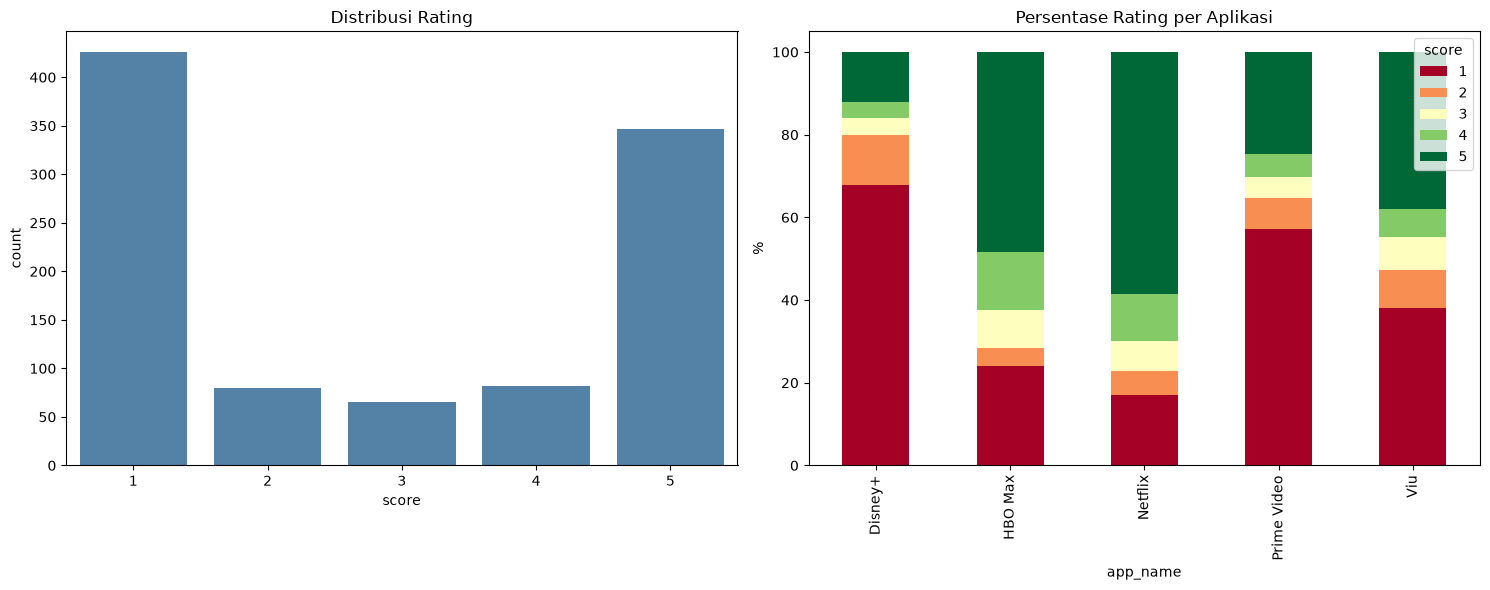

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

sns.countplot(data=df_final, x='score', ax=ax[0], color='steelblue')
ax[0].set_title("Distribusi Rating")

pd.crosstab(df_final['app_name'], df_final['score'], normalize='index').mul(100).plot(
    kind='bar', stacked=True, ax=ax[1], colormap='RdYlGn')
ax[1].set_title("Persentase Rating per Aplikasi")
ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()

2 Kata dominan di setiap rating 

In [14]:
stop = set(stopwords.words('english'))

def simple_tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", str(text).lower())

df_final['tokens'] = df_final['content'].apply(simple_tokenize)

Top 15 kata per rating

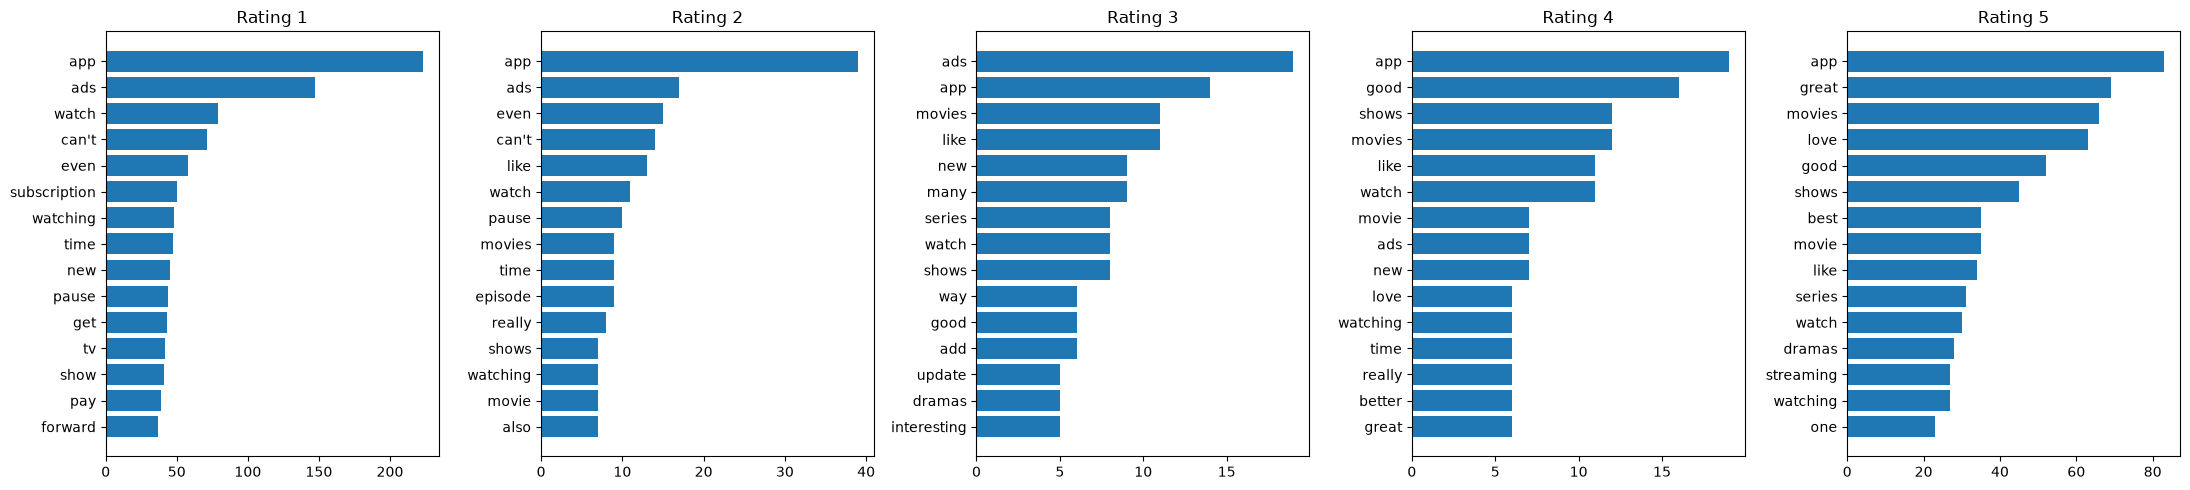

In [15]:
fig, axes = plt.subplots(1, 5, figsize=(22, 5))

for i, r in enumerate(sorted(df_final['score'].unique())):
    cnt = Counter(w for toks in df_final[df_final['score'] == r]['tokens']
                  for w in toks if w not in stop and len(w) > 1)
    top = cnt.most_common(15)
    axes[i].barh([w for w, _ in top][::-1], [c for _, c in top][::-1])
    axes[i].set_title(f"Rating {r}")

plt.tight_layout(); plt.show()

Frasa dominan (bigram)

In [16]:
from sklearn.feature_extraction.text import CountVectorizer

for r in sorted(df_final['score'].unique()):
    cv = CountVectorizer(ngram_range=(2, 2), stop_words='english')
    X = cv.fit_transform(df_final[df_final['score'] == r]['content'].astype(str))
    freq = pd.Series(np.asarray(X.sum(axis=0)).ravel(),
                     index=cv.get_feature_names_out()).sort_values(ascending=False)
    print(f"\nRating {r}:")
    print(freq.head(8))


Rating 1:
new app              20
fast forward         19
prime video          10
ad free               9
forward rewind        9
open app              8
app better            8
continue watching     8
dtype: int64

Rating 2:
fast forward           5
forward pause          4
open app               3
doesn work             2
downloaded videos      2
internet connection    2
ads just               2
access downloads       2
dtype: int64

Rating 3:
movies series         3
increasing feature    2
fast forward          2
video player          2
interesting dramas    2
new interesting       2
new movies            2
pay remove            2
dtype: int64

Rating 4:
good app           3
like netflix       3
don like           3
app doesn          2
commercial free    2
movie series       2
movies shows       2
new app            2
dtype: int64

Rating 5:
hbo max          15
prime video      12
movies series    10
love app          9
easy use          9
asian dramas      8
korean dramas     8
s

3 Cek kata non-standar

In [17]:
english_vocab = set(w.lower() for w in words.words())

def is_standard(w):
    if "'" in w:                 # don't, can't, it's: dianggap standar
        return True
    return w in stop or w in english_vocab or len(wordnet.synsets(w)) > 0

all_tokens = [w for toks in df_final['tokens'] for w in toks]
cnt_all = Counter(all_tokens)

nonstd = {w: c for w, c in cnt_all.items() if not is_standard(w)}
nonstd_series = pd.Series(nonstd).sort_values(ascending=False)

print("Jumlah kata unik non-standar:", len(nonstd_series))
print("Total kemunculan non-standar:", nonstd_series.sum(),
      f"({nonstd_series.sum() / len(all_tokens) * 100:.2f}% dari semua token)")
print(nonstd_series.head(40))

Jumlah kata unik non-standar: 289
Total kemunculan non-standar: 964 (4.32% dari semua token)
app             378
netflix          50
hbo              32
apps             31
viu              29
offline          28
im               17
etc               8
everytime         8
ui                8
youtube           7
others            6
ive               6
lol               5
ott               5
alot              4
uninstall         4
chromecast        4
chromebook        4
hotstar           4
vpn               4
kdrama            4
idk               3
hd                3
glitching         3
unskippable       3
ux                3
glitchy           3
uninstalling      3
qr                3
dazn              3
btw               3
gonna             3
thankyou          2
samsung           2
gotta             2
hdr               2
apk               2
laggy             2
uzalo             2
dtype: int64


4 Perbedaan Antar Aplikasi (Frasa 2-3 Kata)

Setup frasa

In [18]:
from sklearn.feature_extraction.text import CountVectorizer

# Stopword dibuang, tapi kata negasi (not, no, don't, dll.) dipertahankan
# supaya frasa seperti "not working" atau "can't login" tidak rusak
neg_keep = {w for w in stop if w in ('no', 'nor', 'not') or "n't" in w}
custom_stop = list(stop - neg_keep)

cv = CountVectorizer(
    ngram_range=(2, 3),
    stop_words=custom_stop,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b",   # apostrof tidak dipotong
    min_df=3,        # frasa harus muncul di minimal 3 review
    binary=True      # hitung "berapa review yang memuat frasa", bukan total kemunculan
)
X = cv.fit_transform(df_final['content'].astype(str))
phrases = np.array(cv.get_feature_names_out())
print("Jumlah frasa unik:", len(phrases))

Jumlah frasa unik: 344


frasa paling sering per aplikasi

In [19]:
apps = df_final['app_name'].unique()

for app in apps:
    mask = (df_final['app_name'] == app).values
    cnt = np.asarray(X[mask].sum(axis=0)).ravel()
    top = cnt.argsort()[::-1][:10]
    print(f"\n{app} ({mask.sum()} review)")
    for i in top:
        print(f"  {phrases[i]:<30} {cnt[i]} review")


HBO Max (221 review)
  hbo max                        14 review
  shows movies                   6 review
  movies series                  5 review
  many ads                       5 review
  movies shows                   4 review
  customer service               3 review
  streaming service              3 review
  tv shows                       3 review
  love app                       3 review
  good movies                    3 review

Disney+ (255 review)
  fast forward                   25 review
  new app                        21 review
  forward rewind                 9 review
  old app                        9 review
  won't let                      8 review
  love disney                    8 review
  downloaded content             7 review
  downloaded videos              7 review
  disney plus                    7 review
  disney app                     7 review

Prime Video (198 review)
  prime video                    19 review
  amazon prime                   8 review
  

frasa paling khas per aplikasi


HBO Max: frasa khas
               lift  jumlah_review
hbo max        4.52             14
shows movies   2.71              6
movies series  1.51              5
many ads       1.26              5

Disney+: frasa khas
                  lift  jumlah_review
old app           3.92              9
forward rewind    3.92              9
access downloads  3.92              6
app much          3.92              5
skip recap        3.92              5
can't access      3.92              5
disney app        3.92              7
can't fast        3.92              5

Prime Video: frasa khas
              lift  jumlah_review
amazon prime  5.05              8
prime video   4.80             19
not working   3.03              6
many ads      1.96              7

Netflix: frasa khas
               lift  jumlah_review
movies series  1.89              5

Viu: frasa khas
               lift  jumlah_review
asian dramas   6.67              9
korean dramas  6.67              9
viu great      6.67              

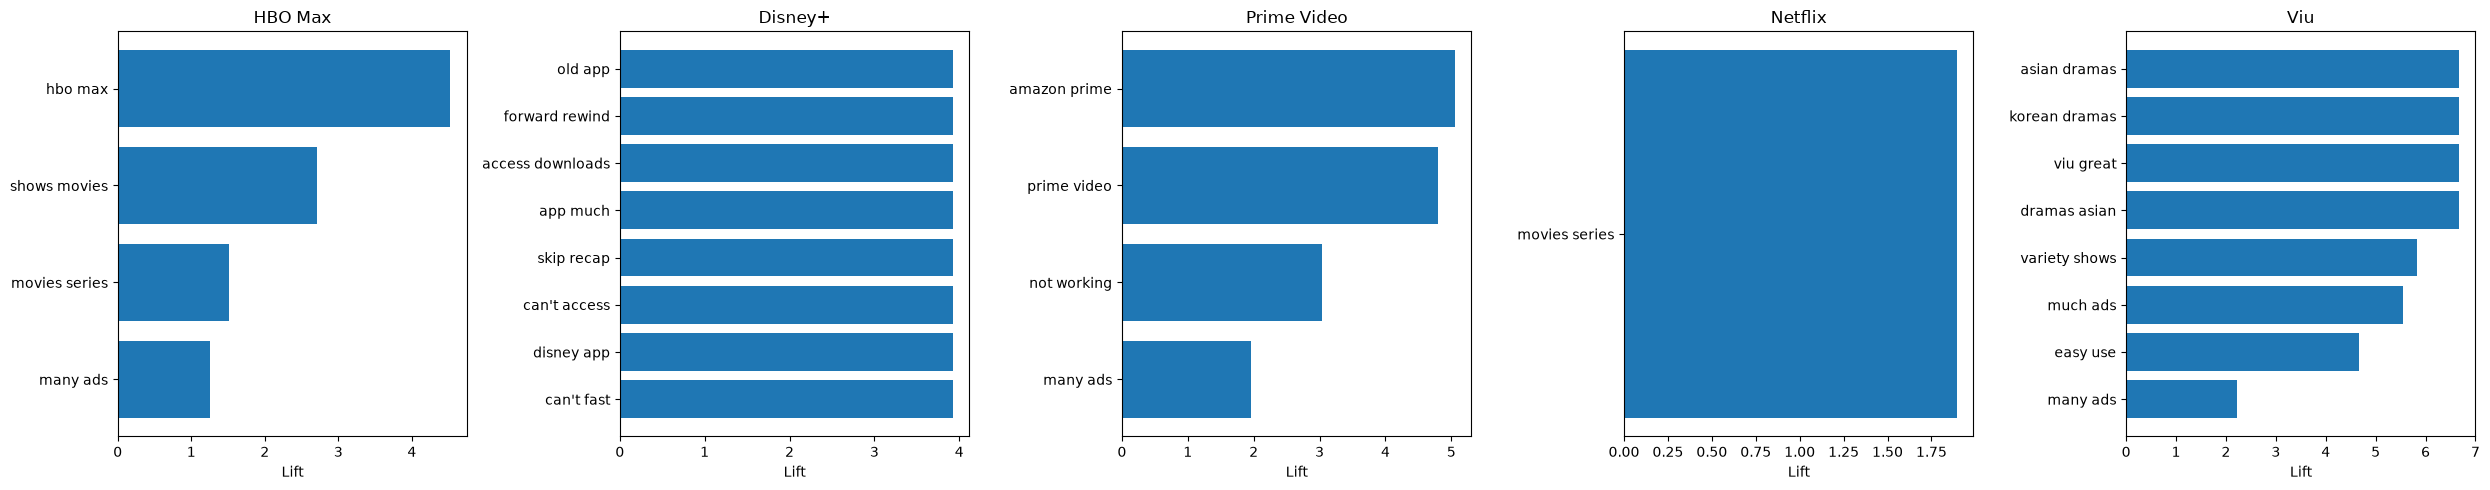

In [20]:
total = np.asarray(X.sum(axis=0)).ravel()
share_all = total / len(df_final)

fig, axes = plt.subplots(1, len(apps), figsize=(5 * len(apps), 5))

for ax, app in zip(axes, apps):
    mask = (df_final['app_name'] == app).values
    cnt = np.asarray(X[mask].sum(axis=0)).ravel()
    lift = (cnt / mask.sum()) / share_all

    s = pd.Series(lift, index=phrases)
    s = s[cnt >= 5]                    
    top = s.sort_values(ascending=False).head(8)

    print(f"\n{app}: frasa khas")
    print(pd.DataFrame({'lift': top.round(2),
                        'jumlah_review': [int(cnt[list(phrases).index(p)]) for p in top.index]}))

    ax.barh(top.index[::-1], top.values[::-1])
    ax.set_title(app)
    ax.set_xlabel("Lift")

plt.tight_layout(); plt.show()

5 Tren waktu

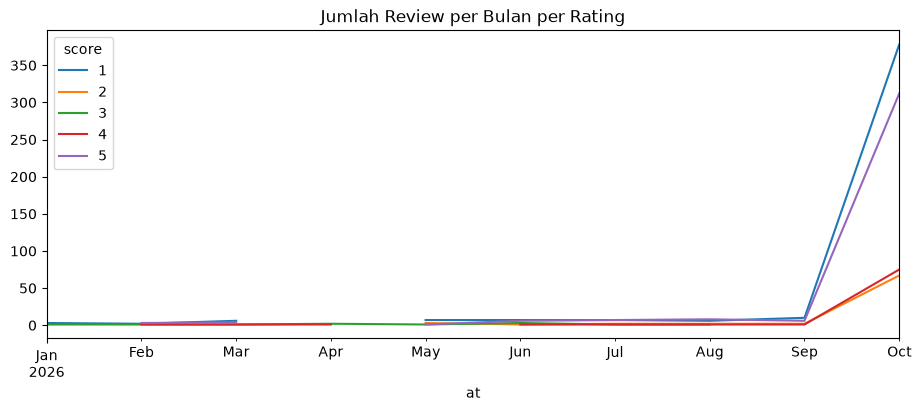

In [21]:
df_final['at'] = pd.to_datetime(df_final['at'])
df_final.groupby([df_final['at'].dt.to_period('M'), 'score']).size().unstack().plot(figsize=(11, 4))
plt.title("Jumlah Review per Bulan per Rating"); plt.show()

## DATA PREPROCESSING

In [22]:
%pip install pyspellchecker -q

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
import pandas as pd, numpy as np, re, html
from collections import Counter
import nltk
for p in ['stopwords','wordnet','omw-1.4','words','averaged_perceptron_tagger','averaged_perceptron_tagger_eng']:
    nltk.download(p, quiet=True)
from nltk.corpus import stopwords, wordnet, words
from nltk.stem import WordNetLemmatizer, PorterStemmer
from nltk import pos_tag
from spellchecker import SpellChecker

# Salinan df_final khusus preprocessing (df_final tetap utuh untuk EDA)
dfp = df_final.copy()
# Alternatif kalau runtime baru: dfp = pd.read_csv("../data/reviews_film.csv")
print(dfp.shape)
dfp.head()

(1000, 5)


,app_name,content,score,at,tokens
0,HBO Max,works good for me,5,2026-10-11 07:31:22,"[works, good, for, me]"
1,Disney+,This is a very bad apps. Keep telling me to do...,1,2026-10-24 23:17:27,"[this, is, a, very, bad, apps, keep, telling, ..."
2,Prime Video,The amount of ads are absolutely horrendous. M...,1,2026-10-26 07:51:17,"[the, amount, of, ads, are, absolutely, horren..."
3,Netflix,It won;t load when I open it,3,2026-10-30 07:16:22,"[it, won, t, load, when, i, open, it]"
4,HBO Max,Thanks Cricket for the subscription to HBO MAX...,5,2026-10-14 13:14:40,"[thanks, cricket, for, the, subscription, to, ..."


## 3.1 Kamus pendukung
Tiga kamus kecil dibuat sendiri berdasarkan temuan EDA:
- **SLANG**: singkatan dan bahasa gaul menjadi bentuk baku.
- **BRANDS**: nama merek/istilah teknis yang tidak boleh dianggap typo (misalnya `netflix`, `roku`, `wifi`). Tanpa ini, spell checker akan mengubah `viu` atau `roku` jadi kata lain.
- **KEEP**: kata negasi dan penguat yang **tidak boleh dibuang** saat stopword removal. `not good` dan `good` artinya berlawanan.

In [24]:
SLANG = {"pls":"please","plz":"please","plss":"please","thx":"thanks","thnx":"thanks","tnx":"thanks",
 "u":"you","ur":"your","r":"are","gud":"good","gd":"good","gr8":"great","nyc":"nice","okey":"okay","ok":"okay",
 "wanna":"want to","gonna":"going to","gotta":"got to","lemme":"let me","dont":"do not","doesnt":"does not",
 "didnt":"did not","isnt":"is not","wont":"will not","couldnt":"could not","wasnt":"was not","cant":"cannot",
 "im":"i am","ive":"i have","bcz":"because","bcoz":"because","coz":"because","cuz":"because","bc":"because",
 "tho":"though","thru":"through","abt":"about","rly":"really","luv":"love","wach":"watch","fav":"favorite",
 "info":"information","acc":"account","acct":"account","vids":"video","vid":"video","eps":"episode","ep":"episode",
 "yr":"year","yrs":"year","mins":"minute","hrs":"hour","ads":"advertisement","ad":"advertisement",
 "lol":"funny","omg":"wow","ya":"you","yea":"yes","yeah":"yes","nah":"no","idk":"i do not know",
 "tbh":"honestly","imo":"in my opinion","btw":"by the way"}

BRANDS = {"netflix","disney","hbo","max","viu","amazon","prime","hulu","roku","google","apple","android","iphone","ios",
 "samsung","chromecast","firestick","tubi","wifi","kdrama","anime","pixar","marvel","espn","hotstar","tv","hd","uhd",
 "vpn","paramount","peacock","crunchyroll","wetv","iqiyi","pc","hdr","fhd","hbomax"}

KEEP = {"no","nor","not","never","cannot","none","nothing","nobody","nowhere","neither","very","too","more","most","only"}
STOP = (set(stopwords.words('english')) - KEEP) | {"s","t","d","ll","m","o","re","ve","y"}

spell = SpellChecker()
spell.distance = 1     # hanya koreksi typo ringan (1 edit), supaya kata tidak diubah jadi kata lain
spell.word_frequency.load_words(list(BRANDS) + ["streaming","stream","buffering","subtitle","subtitles","login","logout",
 "online","offline","download","downloads","downloaded","downloading","unsubscribe","subscription","bluetooth","playback",
 "binge","reinstall","uninstall","update","updates","okay","episode","episodes","advertisement","app","apps"])

lemmatizer, stemmer = WordNetLemmatizer(), PorterStemmer()
print("Jumlah stopword:", len(STOP), "| negasi dipertahankan:", sorted(KEEP & set(stopwords.words('english'))))

Jumlah stopword: 190 | negasi dipertahankan: ['more', 'most', 'no', 'nor', 'not', 'only', 'too', 'very']


## 3.2 Fungsi per tahap
Setiap tahap dibuat sebagai fungsi terpisah supaya bisa didemokan satu per satu dan mudah dijelaskan di video.

In [26]:
# Tahap 2: case folding + hapus URL & HTML
def step_case_fold(t):
    t = html.unescape(str(t)).lower()
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)
    t = re.sub(r"<.*?>", " ", t)
    return t

# Tahap 3: ekspansi kontraksi
def step_contractions(t):
    t = t.replace("’","'").replace("`","'").replace("‘","'")
    t = re.sub(r"\bwon't\b","will not",t); t = re.sub(r"\bcan't\b","cannot",t)
    t = re.sub(r"n't\b"," not",t)
    t = re.sub(r"'re\b"," are",t); t = re.sub(r"'ve\b"," have",t); t = re.sub(r"'ll\b"," will",t)
    t = re.sub(r"\bi'm\b","i am",t); t = re.sub(r"'d\b"," would",t)
    t = re.sub(r"\b(it|he|she|that|there|what|here|who|let)'s\b", r"\1 is", t)
    t = re.sub(r"'s\b","",t)                 # kepemilikan: disney's -> disney
    return t

# Tahap 4: hanya sisakan huruf a-z (hapus emoji, angka, tanda baca)
def step_letters_only(t):
    return re.sub(r"\s+"," ", re.sub(r"[^a-z\s]"," ",t)).strip()

# Tahap 5-7: slang, huruf berulang, typo (per token)
def fix_elongation(w):
    if w in BRANDS or w in spell: return w
    w2 = re.sub(r"(.)\1{2,}", r"\1\1", w)           # gooood -> good, soooo -> soo
    if w2 in spell: return w2
    w1 = re.sub(r"(.)\1+", r"\1", w)                 # soo -> so
    return w1 if w1 in spell else w2

def normalize_token(w):
    if w in SLANG: return SLANG[w].split()           # slang
    w = fix_elongation(w)                            # huruf berulang
    if w in SLANG: return SLANG[w].split()
    if w in BRANDS or w in spell: return [w]         # sudah benar
    c = spell.correction(w)                          # typo
    if c and c != w and len(w) >= 4: return c.split()
    return [w]

# Tahap 8-9: POS tagging + lemmatization
def wn_pos(tag):
    return {'J':wordnet.ADJ,'V':wordnet.VERB,'N':wordnet.NOUN,'R':wordnet.ADV}.get(tag[0], wordnet.NOUN)

LEMMA_FIX = {"apps":"app","tvs":"tv"}
# Kata berakhiran -ing/-ed yang di review berfungsi sebagai KATA SIFAT: jangan diubah jadi kata kerja
# (amazing -> amaze akan mengubah kelas kata dan sedikit mengubah makna)
ADJ_KEEP = {"amazing","amazed","disappointing","disappointed","frustrating","frustrated","annoying","annoyed",
 "boring","bored","confusing","confused","interesting","interested","exciting","excited","pleased","satisfying",
 "satisfied","entertaining","limited","unlimited","broken","outdated","overpriced","unwatchable","relaxing","touching"}
def step_lemmatize(tokens):
    out = []
    for w, tag in pos_tag(tokens):
        if tag[0] in ('N','V') and w not in ADJ_KEEP:  # hanya kata benda & kata kerja
            w = lemmatizer.lemmatize(w, wn_pos(tag))
        w = LEMMA_FIX.get(w, w)
        out.append(w)
    return out

# Tahap 10: stopword removal (negasi dipertahankan)
def step_stopwords(tokens):
    return [w for w in tokens if w not in STOP and (len(w) > 1 or w == "i") and w != "i"]

def preprocess(text, verbose=False):
    t1 = step_case_fold(text)
    t2 = step_contractions(t1)
    t3 = step_letters_only(t2)
    toks = [x for w in t3.split() for x in normalize_token(w)]
    lem = step_lemmatize(toks) if toks else []
    final = step_stopwords(lem)
    if verbose:
        print("1 asli          :", text); print("2 case fold     :", t1); print("3 kontraksi     :", t2)
        print("4 huruf saja    :", t3); print("5-7 slang/typo  :", toks); print("8-9 lemma       :", lem); print("10 stopword     :", final)
    return final

## 3.3 Filter review non-Inggris
Soal 1 meminta review berbahasa Inggris, tetapi `langdetect` bisa meloloskan review bercampur bahasa (Indonesia, Hinglish, Spanyol). Kalau dibiarkan, spell checker akan "memperbaiki" kata asing menjadi kata Inggris yang salah (contoh: `rehta` jadi `rectum`).

Caranya: hitung proporsi token yang dikenal kamus Inggris. Review dengan minimal 5 kata dan proporsi kenal di bawah 65% dianggap bukan Inggris.

In [27]:
def known_ratio(text):
    ws = step_letters_only(step_contractions(step_case_fold(text))).split()
    if not ws: return 0.0, 0
    known = sum(1 for w in ws if w in spell or w in BRANDS or w in SLANG or fix_elongation(w) in spell)
    return known/len(ws), len(ws)

tmp = dfp['content'].apply(known_ratio)
dfp['known_ratio'] = [a for a,b in tmp]; dfp['n_words'] = [b for a,b in tmp]
non_en = dfp[(dfp['known_ratio'] < 0.65) & (dfp['n_words'] >= 5)]
print("Review non-Inggris yang dibuang:", len(non_en))
non_en[['score','known_ratio','content']]

Review non-Inggris yang dibuang: 4


,score,known_ratio,content
546,5,0.600000,very nice but primeam venamee
692,5,0.571429,hi Mahesh gujar cqav vehicle which one 💯☕💌💌💌💌💌
763,5,0.600000,good movie apk for smartphone
948,1,0.250000,app bdo dh byr tetiba log out org tgh sdp tgk ...


In [28]:
dfp = dfp.drop(non_en.index).drop(columns=['known_ratio','n_words']).reset_index(drop=True)
print("Sisa data:", len(dfp))

Sisa data: 996


## 3.4 Demo: satu review diproses tahap demi tahap

In [29]:
preprocess("I can't believe it!! Sooooo goooood, pls add more movies 😍😍 Netflix's apps r the best, wacth them at https://x.co", verbose=True);

1 asli          : I can't believe it!! Sooooo goooood, pls add more movies 😍😍 Netflix's apps r the best, wacth them at https://x.co
2 case fold     : i can't believe it!! sooooo goooood, pls add more movies 😍😍 netflix's apps r the best, wacth them at  
3 kontraksi     : i cannot believe it!! sooooo goooood, pls add more movies 😍😍 netflix apps r the best, wacth them at  
4 huruf saja    : i cannot believe it sooooo goooood pls add more movies netflix apps r the best wacth them at
5-7 slang/typo  : ['i', 'cannot', 'believe', 'it', 'so', 'good', 'please', 'add', 'more', 'movies', 'netflix', 'apps', 'are', 'the', 'best', 'watch', 'them', 'at']
8-9 lemma       : ['i', 'cannot', 'believe', 'it', 'so', 'good', 'please', 'add', 'more', 'movie', 'netflix', 'app', 'be', 'the', 'best', 'watch', 'them', 'at']
10 stopword     : ['cannot', 'believe', 'good', 'please', 'add', 'more', 'movie', 'netflix', 'app', 'best', 'watch']


## 3.5 Terapkan ke seluruh data

In [30]:
dfp['clean_tokens'] = dfp['content'].apply(preprocess)
dfp['clean_text'] = dfp['clean_tokens'].str.join(" ")

empty = dfp['clean_tokens'].str.len() == 0
print("Review kosong setelah preprocessing:", empty.sum())
print(dfp[empty][['score','content']])

Review kosong setelah preprocessing: 1
     score       content
532      5  because 😎 🆒️


In [31]:
dfp = dfp[~empty].reset_index(drop=True)
print("Data akhir:", len(dfp))
print(dfp['score'].value_counts().sort_index())
dfp[['score','content','clean_text']].sample(10, random_state=1)

Data akhir: 995
score
1    425
2     80
3     65
4     82
5    343
Name: count, dtype: int64


,score,content,clean_text
358,1,Disappointing user experience. it is a very gl...,disappointing user experience very glitchy app...
607,4,I like it but having to have specific stuff fo...,like specific stuff thing annoying
808,1,quite possibly the worst app out right now wan...,quite possibly worst app right want watch down...
915,1,Deletes your reviews if you think a show isn't...,deletes review think show not good give constr...
242,4,"Smooth performance and nice interface. Love it!""",smooth performance nice interface love
924,3,Seems better than Netflix. Always google first...,seem better netflix always google first see wa...
262,1,wont work properly offline,not work properly offline
404,1,The amount of ads it plays is absolutely ridic...,amount advertisement play absolutely ridiculou...
318,5,She is wild one you will 😉 😉 😉 😉 😉 yep,wild one yep
49,1,paid for subscription and can't access without...,pay subscription cannot access without delete ...


## 3.6 Bukti: kenapa Lemmatization, bukan Stemming
Stemming memotong akhiran secara kasar, sehingga hasilnya sering bukan kata asli dan bisa mengubah makna/kelas kata (`movies` → `movi`, `service` → `servic`). Lemmatization mengembalikan ke bentuk dasar yang valid dan memakai POS tag, sehingga kelas kata terjaga.

**Keputusan desain:** lemmatization hanya untuk **kata benda dan kata kerja**. Kata sifat dan kata keterangan dibiarkan, karena WordNet akan mengubah `better` → `good` atau `worst` → `bad`, yang menghilangkan tingkat sentimennya. Kata seperti `amazing` atau `disappointing` juga dikecualikan lewat daftar `ADJ_KEEP`, karena di review fungsinya kata sifat, bukan kata kerja.

In [32]:
demo = ["movies","series","subscription","service","watching","episodes","amazing","better","worst","easily","pausing"]
pd.DataFrame({"kata": demo,
              "stemming (Porter)": [stemmer.stem(w) for w in demo],
              "lemmatization (kita)": [step_lemmatize([w])[0] for w in demo]})

,kata,stemming (Porter),lemmatization (kita)
0,movies,movi,movie
1,series,seri,series
2,subscription,subscript,subscription
3,service,servic,service
4,watching,watch,watch
5,episodes,episod,episode
6,amazing,amaz,amazing
7,better,better,better
8,worst,worst,worst
9,easily,easili,easily


## 3.7 Evaluasi: sebelum vs sesudah preprocessing
Diukur dengan definisi "kata standar" yang sama seperti EDA (ada di kamus NLTK/WordNet). Nama merek dan istilah teknis yang wajar (`app`, `offline`, `netflix`, dll.) dihitung standar karena bukan slang atau typo.

In [33]:
english_vocab = set(w.lower() for w in words.words())
raw_stop = set(stopwords.words('english'))
# istilah teknis/merek yang tidak ada di kamus NLTK tapi bukan slang/typo
DOMAIN_OK = BRANDS | {"app","apps","offline","online","uninstall","uninstalling","unsubscribe","ui","etc","youtube","ott","qr",
 "watchlist","imdb","chromebook","login","logout","wifi","subtitle","subtitles","download","downloads","stream","streaming"}
def is_standard(w):
    if "'" in w: return True                       # kontraksi dianggap standar (sama seperti di EDA)
    return w in DOMAIN_OK or w in raw_stop or w in english_vocab or len(wordnet.synsets(w)) > 0

raw_tokens = [w for t in dfp['content'] for w in re.findall(r"[a-z]+(?:'[a-z]+)?", str(t).lower())]
new_tokens = [w for t in dfp['clean_tokens'] for w in t]

def nonstd_pct(toks):
    return sum(not is_standard(w) for w in toks) / len(toks) * 100

summary = pd.DataFrame({
    "Sebelum": [len(raw_tokens), len(set(raw_tokens)), len(raw_tokens)/len(dfp), nonstd_pct(raw_tokens)],
    "Sesudah": [len(new_tokens), len(set(new_tokens)), len(new_tokens)/len(dfp), nonstd_pct(new_tokens)]},
    index=["Total token","Vocabulary (kata unik)","Rata-rata token/review","% token non-standar"]).round(2)
summary

,Sebelum,Sesudah
Total token,22262.00,12710.00
Vocabulary (kata unik),2837.00,2091.00
Rata-rata token/review,22.37,12.77
% token non-standar,1.46,1.31


In [34]:
print("Kata paling sering setelah preprocessing:")
print(Counter(new_tokens).most_common(25))

# Pastikan negasi masih ada
neg = Counter(w for w in new_tokens if w in KEEP)
print("\nNegasi/penguat yang dipertahankan:", dict(neg))

Kata paling sering setelah preprocessing:
[('app', 410), ('not', 335), ('advertisement', 239), ('watch', 239), ('movie', 207), ('show', 176), ('cannot', 145), ('get', 110), ('like', 106), ('good', 100), ('pay', 98), ('time', 94), ('great', 90), ('work', 86), ('love', 85), ('video', 83), ('even', 83), ('no', 82), ('download', 81), ('new', 79), ('subscription', 79), ('more', 79), ('one', 76), ('too', 76), ('very', 70)]

Negasi/penguat yang dipertahankan: {'very': 70, 'nowhere': 2, 'cannot': 145, 'no': 82, 'not': 335, 'never': 20, 'only': 48, 'more': 79, 'too': 76, 'nothing': 8, 'nor': 1, 'neither': 1, 'nobody': 1, 'most': 13, 'none': 3}


## 3.8 Simpan hasil

In [35]:
dfp[['app_name','score','content','clean_text']].to_csv("../data/reviews_film_clean.csv", index=False)
print("Tersimpan:", len(dfp), "baris")

Tersimpan: 995 baris
